# DATA 245 — Person 1: Dataset + EDA
**Project:** Evaluating Classical ML Robustness Under Data Drift (UCI Bank Marketing, `bank-additional-full.csv`)

This notebook loads the data, summarises it, checks data quality, and produces the EDA charts for the mid-presentation.
All charts are saved to `charts/`.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, MUTED, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
    'axes.titlelocation': 'left', 'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

## 1. Load and confirm shape, columns, target, data types

In [2]:
df = pd.read_csv('../data/raw/bank-additional-full.csv', sep=';')   # note: semicolon-separated
print('Shape:', df.shape)
df.dtypes.to_frame('dtype').T

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
dtype,int64,str,str,str,str,str,str,str,str,str,...,int64,int64,int64,str,float64,float64,float64,float64,float64,str


In [3]:
feature_groups = {
    'Customer (7)':          ['age','job','marital','education','default','housing','loan'],
    'Last contact (4)':      ['contact','month','day_of_week','duration'],
    'Campaign history (4)':  ['campaign','pdays','previous','poutcome'],
    'Macroeconomic (5)':     ['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed'],
}
for g, cols in feature_groups.items(): print(f'{g:24s}', cols)
print('Target: y (yes / no) — did the customer subscribe to a term deposit?')

Customer (7)             ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']
Last contact (4)         ['contact', 'month', 'day_of_week', 'duration']
Campaign history (4)     ['campaign', 'pdays', 'previous', 'poutcome']
Macroeconomic (5)        ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Target: y (yes / no) — did the customer subscribe to a term deposit?


## 2. Data quality: missing values, 'unknown' values, duplicates

In [4]:
print('True NaN values:', int(df.isna().sum().sum()))
unk = (df == 'unknown').sum()
unk = unk[unk > 0].sort_values(ascending=False)
unk_tbl = pd.DataFrame({'unknown_count': unk, 'unknown_pct': (unk / len(df) * 100).round(2)})
print('Duplicate rows:', int(df.duplicated().sum()))
print('pdays = 999 (never contacted before):', f"{(df.pdays == 999).mean():.1%}")
unk_tbl

True NaN values: 0
Duplicate rows: 12
pdays = 999 (never contacted before): 96.3%


,unknown_count,unknown_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


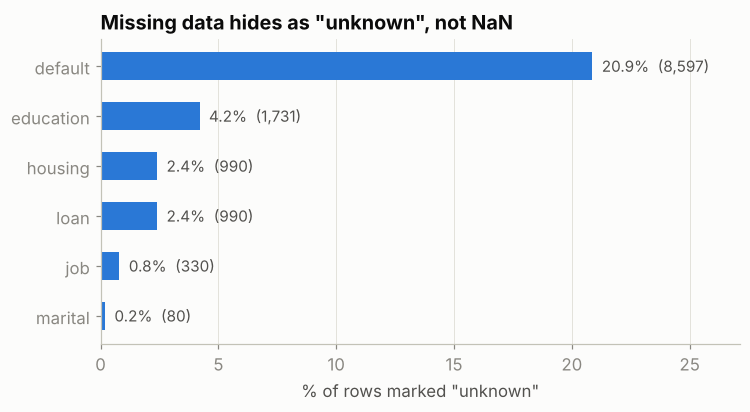

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(unk_tbl.index[::-1], unk_tbl.unknown_pct[::-1], color=BLUE, height=0.55)
for i, (n, p) in enumerate(zip(unk_tbl.unknown_count[::-1], unk_tbl.unknown_pct[::-1])):
    ax.text(p + 0.4, i, f'{p:.1f}%  ({n:,})', va='center', color=INK2, fontsize=10)
ax.set_xlabel('% of rows marked "unknown"'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, unk_tbl.unknown_pct.max() * 1.3)
ax.set_title('Missing data hides as "unknown", not NaN')
fig.savefig('../figures/02_unknown_values.png'); plt.show()

## 3. Target class distribution

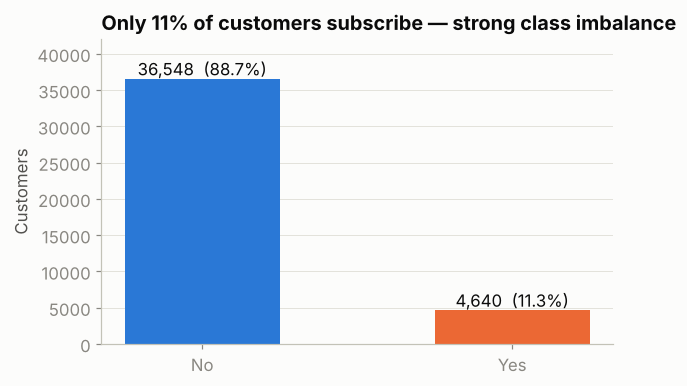

Imbalance ratio (no : yes) = 7.9 : 1


In [6]:
counts = df.y.value_counts()
pct = df.y.value_counts(normalize=True) * 100
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(['No', 'Yes'], [counts['no'], counts['yes']], color=[BLUE, ORANGE], width=0.5)
for b, k in zip(bars, ['no', 'yes']):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 500, f'{counts[k]:,}  ({pct[k]:.1f}%)',
            ha='center', color=INK, fontsize=11)
ax.set_ylabel('Customers'); ax.grid(axis='x', visible=False); ax.set_ylim(0, counts.max() * 1.15)
ax.set_title('Only 11% of customers subscribe — strong class imbalance')
fig.savefig('../figures/01_target_distribution.png'); plt.show()
print('Imbalance ratio (no : yes) = %.1f : 1' % (counts['no'] / counts['yes']))

## 4. Chronological structure
The file has **no year or date column** — only `month` and `day_of_week`. UCI documents that rows are ordered by date, May 2008 → Nov 2010.
We rebuild an approximate period by walking the rows: each time the month goes *backwards* (e.g. Dec → Mar), a new year starts.

In [7]:
mnum = df.month.map({m: i for i, m in enumerate(
    ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'], 1)})
year = 2008 + (mnum.diff() < 0).cumsum()
df['row_order'] = np.arange(len(df))
df['period'] = pd.to_datetime(dict(year=year, month=mnum, day=1))
print('First period:', df.period.min().strftime('%b %Y'), '| Last period:', df.period.max().strftime('%b %Y'))
monthly = df.groupby('period').agg(rows=('y', 'size'), yes_rate=('y', lambda s: (s == 'yes').mean() * 100),
                                   euribor3m=('euribor3m', 'mean'), nr_employed=('nr.employed', 'mean'))
monthly.round(2)

First period: May 2008 | Last period: Nov 2010


,rows,yes_rate,euribor3m,nr_employed
period,,,,
2008-05-01,7763,3.09,4.86,5191.0
2008-06-01,4374,4.30,4.93,5228.1
2008-07-01,6685,6.09,4.96,5228.1
2008-08-01,5175,5.24,4.96,5228.1
2008-10-01,67,62.69,4.92,5195.8
2008-11-01,3616,5.25,4.11,5195.8
2008-12-01,10,10.00,3.49,5176.3
2009-03-01,282,44.68,1.65,5099.1
2009-04-01,2458,17.98,1.41,5099.1


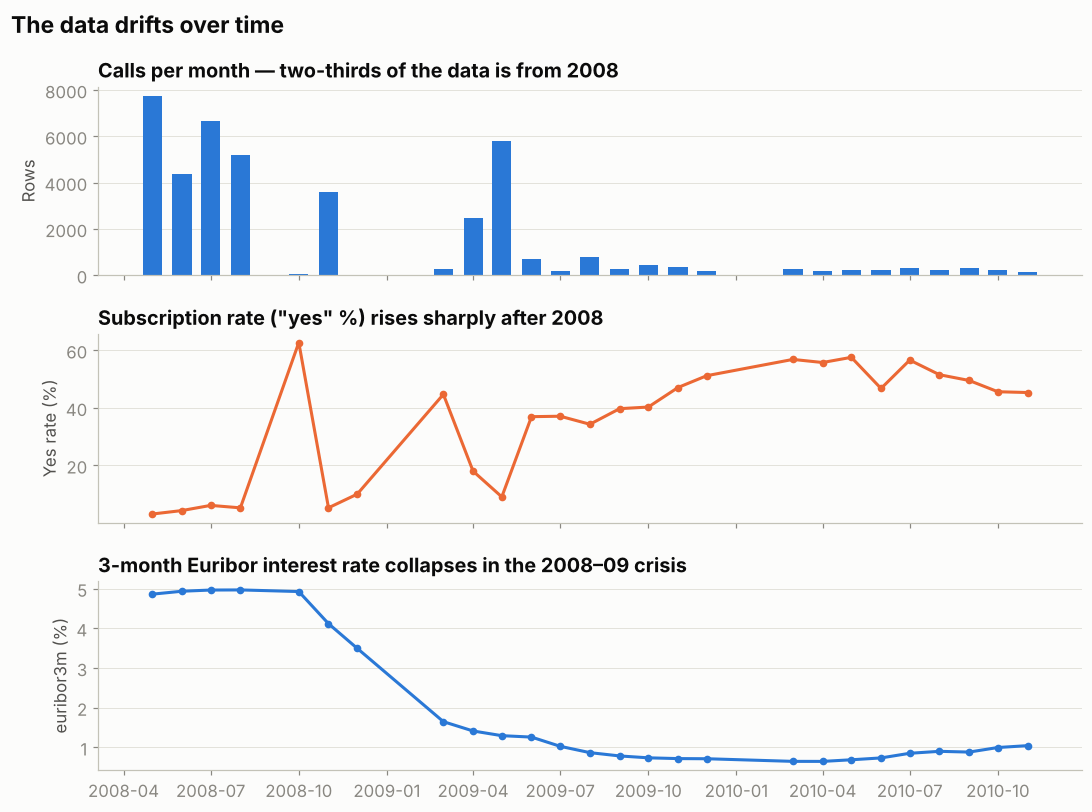

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
x = monthly.index
axes[0].bar(x, monthly.rows, width=20, color=BLUE)
axes[0].set_title('Calls per month — two-thirds of the data is from 2008'); axes[0].set_ylabel('Rows')
axes[1].plot(x, monthly.yes_rate, color=ORANGE, lw=2, marker='o', ms=4)
axes[1].set_title('Subscription rate ("yes" %) rises sharply after 2008'); axes[1].set_ylabel('Yes rate (%)')
axes[2].plot(x, monthly.euribor3m, color=BLUE, lw=2, marker='o', ms=4)
axes[2].set_title('3-month Euribor interest rate collapses in the 2008–09 crisis'); axes[2].set_ylabel('euribor3m (%)')
for a in axes: a.grid(axis='x', visible=False)
fig.suptitle('The data drifts over time', x=0.01, ha='left', fontsize=15, fontweight='bold', color=INK)
fig.tight_layout(); fig.savefig('../figures/03_drift_over_time.png'); plt.show()

### Early vs. late window
Compare the first 70% of rows (what a model would train on) with the last 30% (what it would be tested on).
KS test = are the two distributions different? PSI = how big is the shift (>0.25 is usually called a major shift).

In [9]:
cut = int(len(df) * 0.7)
early, late = df.iloc[:cut], df.iloc[cut:]

def psi(a, b, bins=10):
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    pa = np.histogram(a, edges)[0] / len(a); pb = np.histogram(b, edges)[0] / len(b)
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))

rows = []
for c in ['age', 'campaign', 'euribor3m', 'emp.var.rate', 'nr.employed', 'cons.conf.idx', 'cons.price.idx']:
    ks = ks_2samp(early[c], late[c])
    rows.append({'feature': c, 'early_mean': early[c].mean(), 'late_mean': late[c].mean(),
                 'KS_stat': ks.statistic, 'KS_p': ks.pvalue, 'PSI': psi(early[c].values, late[c].values)})
drift_tbl = pd.DataFrame(rows).set_index('feature')
drift_tbl['shift'] = pd.cut(drift_tbl.PSI, [-1, 0.1, 0.25, 99], labels=['small', 'moderate', 'major'])
print('Yes rate — early: %.1f%%  late: %.1f%%' % ((early.y == 'yes').mean() * 100, (late.y == 'yes').mean() * 100))
drift_tbl.round(3)

Yes rate — early: 5.6%  late: 24.6%


,early_mean,late_mean,KS_stat,KS_p,PSI,shift
feature,,,,,,
age,40.177,39.666,0.095,0.0,0.117,moderate
campaign,2.768,2.099,0.090,0.0,0.050,small
euribor3m,4.685,1.138,0.996,0.0,8.486,major
emp.var.rate,1.000,-2.061,0.960,0.0,11.518,major
nr.employed,5208.861,5069.450,0.960,0.0,11.324,major
cons.conf.idx,-39.793,-42.158,0.586,0.0,4.477,major
cons.price.idx,93.810,93.029,0.794,0.0,5.058,major


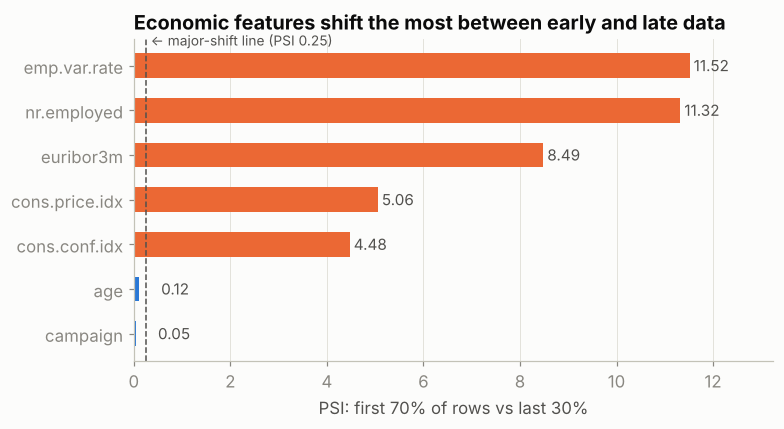

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
t = drift_tbl.sort_values('PSI')
cols = [ORANGE if v > 0.25 else BLUE for v in t.PSI]
ax.barh(t.index, t.PSI.clip(upper=t.PSI.max()), color=cols, height=0.55)
ax.axvline(0.25, color=INK2, lw=1, ls='--'); ax.text(0.35, len(t) - 0.55, '← major-shift line (PSI 0.25)', color=INK2, fontsize=9)
for i, v in enumerate(t.PSI): ax.text(v + 0.45 if v < 1 else v + 0.08, i, f'{v:.2f}', va='center', color=INK2, fontsize=10)
ax.set_xlabel('PSI: first 70% of rows vs last 30%'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, t.PSI.max() * 1.15)
ax.set_title('Economic features shift the most between early and late data')
fig.savefig('../figures/04_early_vs_late_psi.png'); plt.show()

## 5. Macroeconomic features move together

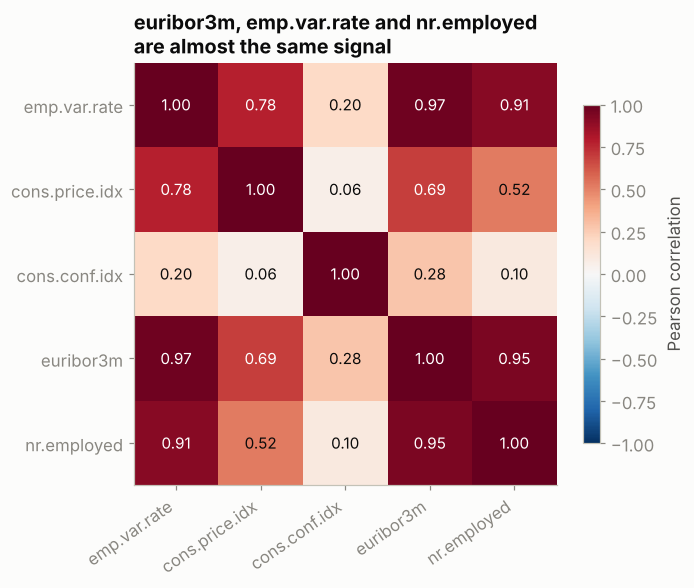

In [11]:
macro = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
corr = df[macro].corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(5), macro, rotation=35, ha='right'); ax.set_yticks(range(5), macro); ax.grid(False)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > 0.6 else INK, fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson correlation')
ax.set_title('euribor3m, emp.var.rate and nr.employed\nare almost the same signal')
fig.savefig('../figures/05_macro_correlation.png'); plt.show()

## 6. Leakage check: `duration`
`duration` = length of the call in seconds. It is only known **after** the call ends, so it can't be used to decide whom to call.
It is also extremely predictive — which is exactly why keeping it would give fake, inflated scores.

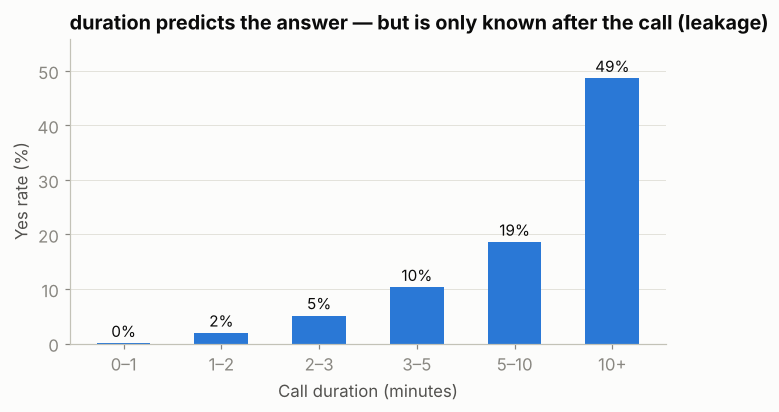

duration = 0 rows: 4 — all are "no"


In [12]:
bins = [-1, 60, 120, 180, 300, 600, 10_000]
labels = ['0–1', '1–2', '2–3', '3–5', '5–10', '10+']
g = df.assign(b=pd.cut(df.duration, bins, labels=labels)).groupby('b', observed=True).y.apply(lambda s: (s == 'yes').mean() * 100)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(g.index.astype(str), g.values, color=BLUE, width=0.55)
for i, v in enumerate(g.values): ax.text(i, v + 1.2, f'{v:.0f}%', ha='center', color=INK, fontsize=10)
ax.set_xlabel('Call duration (minutes)'); ax.set_ylabel('Yes rate (%)'); ax.grid(axis='x', visible=False)
ax.set_ylim(0, g.max() * 1.15)
ax.set_title('duration predicts the answer — but is only known after the call (leakage)')
fig.savefig('../figures/06_duration_leakage.png'); plt.show()
print('duration = 0 rows:', int((df.duration == 0).sum()), '— all are "no"' if (df[df.duration == 0].y == 'no').all() else '')

## 7. Save the shared dataset for the team

In [13]:
out = df.drop(columns=['duration'])
out.to_csv('../data/processed/bank_marketing_for_modeling.csv', index=False)
print('Saved bank_marketing_for_modeling.csv:', out.shape,
      '\n- duration removed (leakage)\n- row_order + period added (chronological order kept)'
      '\n- "unknown" kept as its own category, duplicates kept (decide in preprocessing)')

Saved bank_marketing_for_modeling.csv: (41188, 22) 
- duration removed (leakage)
- row_order + period added (chronological order kept)
- "unknown" kept as its own category, duplicates kept (decide in preprocessing)


## Key notes for the team
- **41,188 rows, 20 inputs, target `y`.** No true NaNs, but six categorical columns use `"unknown"` — `default` is 20.9% unknown.
- **Imbalance:** 88.7% no / 11.3% yes (~7.9 : 1). Accuracy is misleading; use F1, Recall, PR-AUC.
- **Chronology:** no date column; rows are ordered May 2008 → Nov 2010. about two-thirds (67%) of rows are from 2008, before the Euribor collapse.
- **Drift is real:** the late window has a much higher yes rate and very different macro values (PSI well above 0.25).
- **Macro features are highly correlated** and largely track time.
- **`duration` is leakage** — removed in the shared file.
- **12 exact duplicate rows** — kept for now; preprocessing can drop them.